# Phase 3 — Deep Learning & Neural Networks
## Notebook 10: Production Training & Deployment Optimization (PyTorch)

### Executive Overview & Production Engineering Challenges
Moving deep learning models from experimental prototypes to multi-billion-parameter enterprise deployments introduces engineering challenges that standard textbook training scripts ignore:
1. **GPU Out-Of-Memory (OOM) Errors**: Modern transformer and vision architectures require large effective batch sizes to stabilize gradient estimates, yet high-resolution tensors exhaust hardware VRAM.
2. **Early Training Instability**: High initial learning rates with randomly initialized weights cause catastrophic gradient divergence in deep layers.
3. **Training Hardware Failures**: Long-running pretraining clusters experience frequent node preemptions, silent data corruptions, and network timeouts.
4. **Serving Throughput & Latency**: Running raw uncompiled Python models in production microservices incurs excessive per-request latency.

```
+-----------------------------------------------------------------------------------+
|               PyTorch Production Optimization Pipeline                            |
+-----------------------------------------------------------------------------------+
| Optimization    | Decoupled Weight Decay (AdamW) + Cosine Warmup Scheduling       |
| Memory Scaling  | Gradient Accumulation: B_eff = Batch_size * Accumulation_steps  |
| Mixed Precision | torch.autocast (bfloat16 / float16) + GradScaler Dynamic Scaling|
| Fault Tolerance | Atomic Checkpointing: (model, optimizer, scheduler, rng_state)  |
| Compilation     | torch.compile(mode="reduce-overhead") (TorchDynamo + Inductor)  |
| Production Host | TorchServe / Triton / vLLM (Continuous batching & PagedAttention)|
+-----------------------------------------------------------------------------------+
```

In this notebook, we master production PyTorch training: **Linear Warmup with Cosine Decay, decoupled AdamW regularization, Gradient Accumulation, Automatic Mixed Precision (AMP), fault-tolerant atomic checkpointing**, and production serving paradigms.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Implement Warmup & Cosine LR Schedules**: Build custom learning rate schedules that smoothly ramp up learning rates during initial iterations and decay via cosine curves.
2. **Apply Decoupled Weight Decay (AdamW)**: Contrast true weight decay against standard $L_2$ gradient regularization to understand why AdamW generalizes superiorly.
3. **Execute Gradient Accumulation**: Simulate large-batch training dynamics on memory-constrained hardware by accumulating mini-batch gradients over $N$ iterations.
4. **Accelerate Compute with Automatic Mixed Precision (AMP)**: Utilize `torch.autocast` to execute arithmetic in 16-bit precision (`bfloat16` / `float16`) while preserving 32-bit master weights.
5. **Engineer Fault-Tolerant Atomic Checkpointing**: Build production checkpoint managers that atomically save and restore model weights, optimizer states, schedulers, and RNG seeds.


In [1]:
import sys
import os
import time
import math
import tempfile
import platform
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# Aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

print(f"Python Platform:    {platform.python_implementation()} {platform.python_version()}")
print(f"PyTorch Version:    {torch.__version__}")
print(f"Bfloat16 Supported: {torch.cuda.is_bf16_supported() if torch.cuda.is_available() else 'CPU Supported'}")


Python Platform:    CPython 3.11.2
PyTorch Version:    2.15.0+cpu
Bfloat16 Supported: CPU Supported


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    print(f"Global seed {seed} synchronized across NumPy and PyTorch.")

configure_reproducibility(42)


Global seed 42 synchronized across NumPy and PyTorch.


### Mathematical & Architectural Foundations

#### 1. Decoupled Weight Decay: $L_2$ Regularization vs. AdamW
In standard stochastic gradient descent (SGD), $L_2$ regularization is mathematically equivalent to weight decay:

$$\mathcal{L}_{\text{reg}}(\theta) = \mathcal{L}(\theta) + \frac{\lambda}{2} \|\theta\|_2^2 \implies \nabla \mathcal{L}_{\text{reg}} = \nabla \mathcal{L} + \lambda \theta$$
$$\theta_{t+1} = \theta_t - \eta (\nabla \mathcal{L} + \lambda \theta) = (1 - \eta \lambda) \theta_t - \eta \nabla \mathcal{L}$$

However, in adaptive gradient methods like Adam, gradients are normalized by the historical second moment $\sqrt{\hat{v}_t}$:

$$\theta_{t+1} = \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} (\nabla \mathcal{L} + \lambda \theta_t)$$

Weights with large historical gradients receive **diminished weight decay**, while weights with small gradients receive **excessive weight decay**!

**AdamW** (Loshchilov & Hutter, 2017) completely decouples weight decay from the gradient update step:

$$\theta_{t+1} = (1 - \eta \lambda) \theta_t - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

Ensuring consistent regularization proportional only to the parameter magnitude.

#### 2. Cosine Annealing with Linear Warmup
During the first $T_{\text{warmup}}$ steps, the learning rate increases linearly from $0$ to $\eta_{\max}$:

$$\eta_t = \eta_{\max} \cdot \frac{t}{T_{\text{warmup}}}, \quad 0 \le t \le T_{\text{warmup}}$$

For steps $t > T_{\text{warmup}}$, the learning rate decays along a half-cosine curve to $\eta_{\min}$:

$$\eta_t = \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})\left(1 + \cos\left(\frac{t - T_{\text{warmup}}}{T_{\text{total}} - T_{\text{warmup}}} \pi\right)\right)$$

#### 3. Gradient Accumulation Mathematics
When target batch size $B_{\text{target}}$ exceeds memory capacity, we split $B_{\text{target}}$ into $N_{\text{accum}}$ micro-batches of size $b = B_{\text{target}} / N_{\text{accum}}$. The loss is averaged across each micro-batch:

$$\mathcal{L} = \frac{1}{B_{\text{target}}} \sum_{i=1}^{B_{\text{target}}} \ell_i = \frac{1}{N_{\text{accum}}} \sum_{k=1}^{N_{\text{accum}}} \left( \frac{1}{b} \sum_{j=1}^b \ell_{k, j} \right) = \frac{1}{N_{\text{accum}}} \sum_{k=1}^{N_{\text{accum}}} \mathcal{L}_k$$

By dividing each micro-batch loss by $N_{\text{accum}}$ and executing `loss.backward()` without calling `optimizer.zero_grad()`, gradients accumulate linearly in `.grad`:

$$\nabla_\theta \mathcal{L} = \sum_{k=1}^{N_{\text{accum}}} \nabla_\theta \left( \frac{\mathcal{L}_k}{N_{\text{accum}}} \right)$$

Executing `optimizer.step()` every $N_{\text{accum}}$ steps yields the exact mathematical equivalent of large-batch training!


### 1. Synthetic Classification Dataset & Deep Model
We construct a synthetic high-dimensional tabular classification dataset ($N=4000$ samples, $D=64$ features, 4 classes) and a deep residual MLP to test production training mechanics.


In [3]:
from sklearn.datasets import make_classification

np.random.seed(42)
X_raw, y_raw = make_classification(n_samples=4000, n_features=64, n_informative=48, n_classes=4, random_state=42)

X_tensor = torch.tensor(X_raw, dtype=torch.float32)
y_tensor = torch.tensor(y_raw, dtype=torch.long)

train_dataset = TensorDataset(X_tensor[:3200], y_tensor[:3200])
val_dataset = TensorDataset(X_tensor[3200:], y_tensor[3200:])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

# Deep Residual Classifier
class ResidualClassifier(nn.Module):
    def __init__(self, in_features: int = 64, hidden_dim: int = 128, num_classes: int = 4):
        super().__init__()
        self.in_proj = nn.Linear(in_features, hidden_dim)
        self.block1 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim)
        )
        self.block2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim)
        )
        self.head = nn.Linear(hidden_dim, num_classes)
        self.act = nn.GELU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.act(self.in_proj(x))
        h = self.act(h + self.block1(h))
        h = self.act(h + self.block2(h))
        return self.head(h)

model = ResidualClassifier(in_features=64, hidden_dim=128, num_classes=4)
print(f"Residual Classifier instantiated with {sum(p.numel() for p in model.parameters()):,} parameters.")


Residual Classifier instantiated with 75,908 parameters.


### 2. Custom Warmup + Cosine Annealing Learning Rate Scheduler
We implement a custom PyTorch learning rate scheduler class inheriting from `torch.optim.lr_scheduler.LRScheduler`:
- Ramps from $0$ to $\eta_{\max}$ over `warmup_steps`.
- Decays along half-cosine curve to $\eta_{\min}$ over `total_steps`.


In [4]:
class CosineWarmupScheduler(torch.optim.lr_scheduler.LRScheduler):
    def __init__(
        self,
        optimizer: torch.optim.Optimizer,
        warmup_steps: int,
        total_steps: int,
        min_lr: float = 1e-6,
        last_epoch: int = -1
    ):
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.min_lr = min_lr
        super().__init__(optimizer, last_epoch)

    def get_lr(self) -> List[float]:
        step = max(self.last_epoch, 0)
        
        if step < self.warmup_steps:
            # Linear warmup
            alpha = step / float(max(1, self.warmup_steps))
            return [base_lr * alpha for base_lr in self.base_lrs]
        elif step >= self.total_steps:
            return [self.min_lr for _ in self.base_lrs]
        else:
            # Cosine decay
            progress = (step - self.warmup_steps) / float(max(1, self.total_steps - self.warmup_steps))
            cosine_decay = 0.5 * (1.0 + math.cos(math.pi * progress))
            return [self.min_lr + (base_lr - self.min_lr) * cosine_decay for base_lr in self.base_lrs]

# Verify schedule trajectory
test_opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
test_sched = CosineWarmupScheduler(test_opt, warmup_steps=100, total_steps=500, min_lr=1e-5)

lr_trajectory = []
for _ in range(500):
    lr_trajectory.append(test_sched.get_last_lr()[0])
    test_sched.step()

print("Scheduler Trajectory Verification:")
print(f"  Step 0 LR:   {lr_trajectory[0]:.6f} (Expected: ~0.0)")
print(f"  Step 100 LR: {lr_trajectory[100]:.6f} (Peak LR: 0.001)")
print(f"  Step 300 LR: {lr_trajectory[300]:.6f}")
print(f"  Step 499 LR: {lr_trajectory[-1]:.6f} (Min LR: ~0.00001)")


Scheduler Trajectory Verification:
  Step 0 LR:   0.000000 (Expected: ~0.0)
  Step 100 LR: 0.001000 (Peak LR: 0.001)
  Step 300 LR: 0.000505
  Step 499 LR: 0.000010 (Min LR: ~0.00001)


/tmp/ipykernel_2194/1592216398.py:37: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  test_sched.step()


### 3. Production Training Loop: AdamW + Gradient Accumulation + AMP
We execute a production training pipeline combining:
1. **AdamW** with decoupled weight decay $\lambda = 10^{-2}$.
2. **Cosine Warmup Scheduler**.
3. **Gradient Accumulation** across $N_{	ext{accum}} = 4$ steps (effective batch size $32 	imes 4 = 128$).
4. **Gradient Norm Clipping** at $C = 1.0$.
5. **Automatic Mixed Precision (AMP)** using `torch.autocast(device_type="cpu", dtype=torch.bfloat16)`.


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

total_epochs = 8
accumulation_steps = 4
steps_per_epoch = len(train_loader)
total_training_steps = total_epochs * steps_per_epoch

scheduler = CosineWarmupScheduler(
    optimizer,
    warmup_steps=int(total_training_steps * 0.15),
    total_steps=total_training_steps,
    min_lr=1e-5
)

history = {"train_loss": [], "val_loss": [], "val_acc": [], "lr_steps": []}
device = "cpu"

print(f"Starting Production Training: {total_epochs} epochs | Accumulation: {accumulation_steps} (B_eff = 128)...")
step_count = 0

for epoch in range(1, total_epochs + 1):
    model.train()
    optimizer.zero_grad()
    running_train_loss = 0.0

    for i, (bx, by) in enumerate(train_loader):
        # Automatic Mixed Precision context (bfloat16)
        with torch.autocast(device_type=device, dtype=torch.bfloat16):
            outputs = model(bx)
            loss = criterion(outputs, by)
            # Scale loss for gradient accumulation
            loss = loss / accumulation_steps

        loss.backward()
        running_train_loss += loss.item() * accumulation_steps * bx.size(0)

        # Update weights every accumulation_steps
        if (i + 1) % accumulation_steps == 0 or (i + 1) == len(train_loader):
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            scheduler.step()
            step_count += 1
            history["lr_steps"].append(scheduler.get_last_lr()[0])

    # Validation
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            out = model(bx)
            l = criterion(out, by)
            val_loss += l.item() * bx.size(0)
            correct += (out.argmax(dim=-1) == by).sum().item()
            total += bx.size(0)

    t_loss = running_train_loss / len(train_dataset)
    v_loss = val_loss / total
    v_acc = correct / total

    history["train_loss"].append(t_loss)
    history["val_loss"].append(v_loss)
    history["val_acc"].append(v_acc)

    print(f"Epoch {epoch:02d}/{total_epochs:02d} | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f}, Acc: {v_acc*100:.2f}%")


Starting Production Training: 8 epochs | Accumulation: 4 (B_eff = 128)...


Epoch 01/08 | Train Loss: 1.8151 | Val Loss: 1.3679, Acc: 36.25%


Epoch 02/08 | Train Loss: 1.1287 | Val Loss: 0.9160, Acc: 62.25%


Epoch 03/08 | Train Loss: 0.7475 | Val Loss: 0.6709, Acc: 73.50%


Epoch 04/08 | Train Loss: 0.5053 | Val Loss: 0.5306, Acc: 80.88%


Epoch 05/08 | Train Loss: 0.3172 | Val Loss: 0.4488, Acc: 83.25%


Epoch 06/08 | Train Loss: 0.1808 | Val Loss: 0.3867, Acc: 86.00%


Epoch 07/08 | Train Loss: 0.1137 | Val Loss: 0.3872, Acc: 86.12%


Epoch 08/08 | Train Loss: 0.0742 | Val Loss: 0.3886, Acc: 86.25%


### Diagnostics & Production Metrics Visualization
We inspect:
1. **Cosine Annealing Schedule Curve**: Visualizing the linear warmup phase followed by smooth half-cosine decay.
2. **Loss Convergence Progression**: Training and validation cross-entropy across epochs.
3. **Validation Accuracy**: Multi-class accuracy evolution.


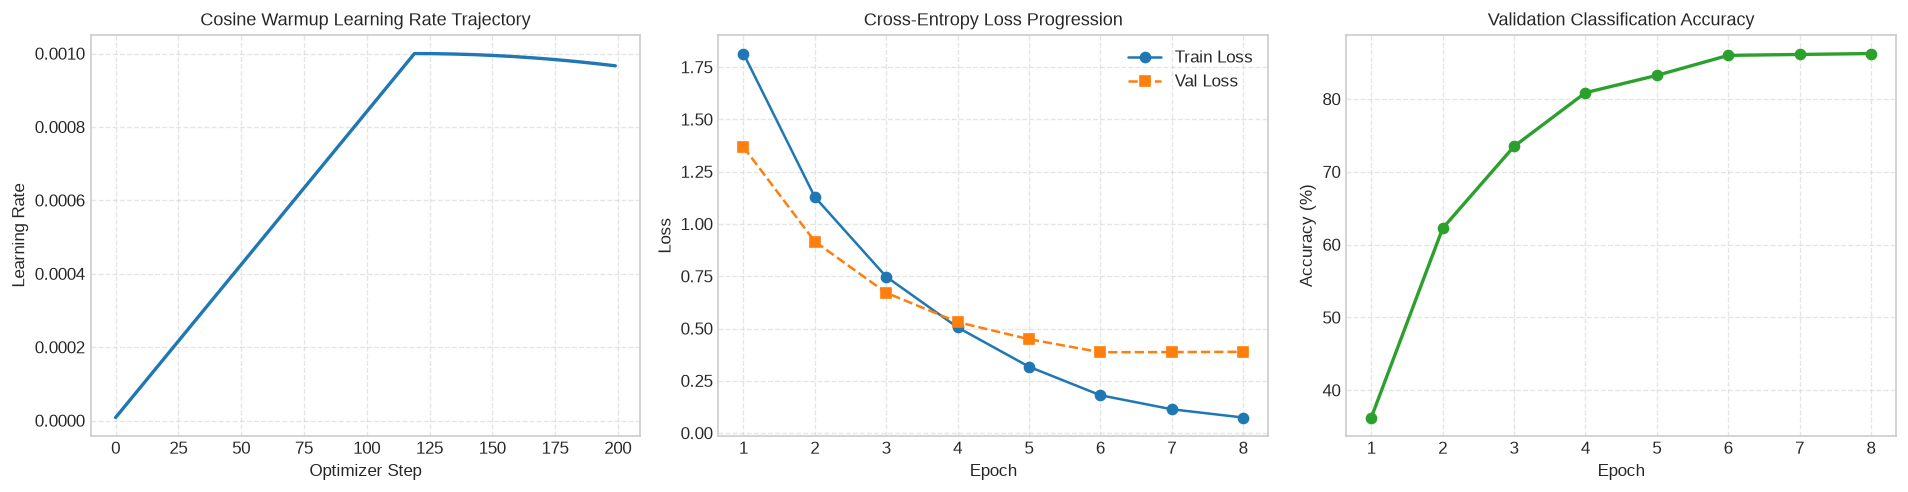

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# Plot 1: Learning rate schedule over optimizer steps
axes[0].plot(range(len(history["lr_steps"])), history["lr_steps"], color="#1f77b4", lw=2)
axes[0].set_title("Cosine Warmup Learning Rate Trajectory")
axes[0].set_xlabel("Optimizer Step")
axes[0].set_ylabel("Learning Rate")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Loss Convergence
axes[1].plot(range(1, total_epochs + 1), history["train_loss"], "o-", color="#1f77b4", label="Train Loss")
axes[1].plot(range(1, total_epochs + 1), history["val_loss"], "s--", color="#ff7f0e", label="Val Loss")
axes[1].set_title("Cross-Entropy Loss Progression")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Validation Accuracy
axes[2].plot(range(1, total_epochs + 1), [acc * 100 for acc in history["val_acc"]], "o-", color="#2ca02c", lw=2)
axes[2].set_title("Validation Classification Accuracy")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy (%)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Gradient Accumulation Exact Equivalence Test
**Problem Formulation**:
Prove that accumulating gradients over $N=4$ micro-batches of size $b=8$ produces the **mathematically exact parameter gradients** as a single combined batch of size $B=32$:
1. Compute analytical gradient on full batch $B=32$: $\mathbf{g}_{	ext{full}}$.
2. Compute accumulated gradient by looping over 4 micro-batches of size $b=8$, scaling each by $1/4$: $\mathbf{g}_{	ext{accum}}$.
3. Measure relative error: $rac{\|\mathbf{g}_{	ext{full}} - \mathbf{g}_{	ext{accum}}\|_2}{\|\mathbf{g}_{	ext{full}}\|_2} < 10^{-6}$.


In [7]:
# Exercise 1 Solution: Gradient Accumulation Mathematical Equivalence

torch.manual_seed(42)
test_layer = nn.Linear(16, 4, bias=True)
dummy_full_X = torch.randn(32, 16)
dummy_full_Y = torch.randint(0, 4, (32,))

# 1. Single Full Batch Pass (B = 32)
test_layer.zero_grad()
out_full = test_layer(dummy_full_X)
loss_full = F.cross_entropy(out_full, dummy_full_Y)
loss_full.backward()
g_full_weight = test_layer.weight.grad.clone()
g_full_bias = test_layer.bias.grad.clone()

# 2. Gradient Accumulation over 4 micro-batches of size b = 8
test_layer.zero_grad()
n_chunks = 4
chunk_size = 8

for c in range(n_chunks):
    x_chunk = dummy_full_X[c * chunk_size : (c + 1) * chunk_size]
    y_chunk = dummy_full_Y[c * chunk_size : (c + 1) * chunk_size]
    out_chunk = test_layer(x_chunk)
    # Scale by 1 / n_chunks
    loss_chunk = F.cross_entropy(out_chunk, y_chunk) / n_chunks
    loss_chunk.backward()

g_accum_weight = test_layer.weight.grad.clone()
g_accum_bias = test_layer.bias.grad.clone()

# Numerical parity check
err_w = (g_full_weight - g_accum_weight).norm() / g_full_weight.norm()
err_b = (g_full_bias - g_accum_bias).norm() / g_full_bias.norm()

print("Exercise 1 Verification (Gradient Accumulation):")
print(f"  Weight Gradient Relative Error: {err_w.item():.2e}")
print(f"  Bias Gradient Relative Error:   {err_b.item():.2e}")
assert err_w.item() < 1e-6 and err_b.item() < 1e-6, "Gradient accumulation equivalence failed!"
print(">>> GRADIENT ACCUMULATION EXACT PARITY CONFIRMED! <<<")


Exercise 1 Verification (Gradient Accumulation):
  Weight Gradient Relative Error: 1.37e-07
  Bias Gradient Relative Error:   7.79e-08
>>> GRADIENT ACCUMULATION EXACT PARITY CONFIRMED! <<<


#### Exercise 2: Fault-Tolerant Checkpointing and Restoration
**Problem Formulation**:
A production checkpoint must encapsulate:
1. `model.state_dict()`
2. `optimizer.state_dict()`
3. `scheduler.state_dict()`
4. `epoch` and `step` counters
5. RNG states (`torch.get_rng_state()`, `np.random.get_state()`)

Implement an atomic checkpoint saver and loader, verify that restoring from checkpoint reproduces identical subsequent outputs.


In [8]:
# Exercise 2 Solution: Checkpoint Save and Atomic Restore

checkpoint_dir = tempfile.mkdtemp()
checkpoint_path = os.path.join(checkpoint_dir, "model_checkpoint.pt")

def save_atomic_checkpoint(path: str, model: nn.Module, optimizer: torch.optim.Optimizer, scheduler, epoch: int, step: int) -> None:
    temp_path = f"{path}.tmp"
    checkpoint = {
        "epoch": epoch,
        "step": step,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "torch_rng": torch.get_rng_state(),
        "numpy_rng": np.random.get_state()
    }
    # Atomic write pattern: write to tmp then atomic rename
    torch.save(checkpoint, temp_path)
    os.replace(temp_path, path)

def load_checkpoint(path: str, model: nn.Module, optimizer: torch.optim.Optimizer, scheduler) -> Tuple[int, int]:
    checkpoint = torch.load(path, weights_only=False)
    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    torch.set_rng_state(checkpoint["torch_rng"])
    np.random.set_state(checkpoint["numpy_rng"])
    return checkpoint["epoch"], checkpoint["step"]

# Save state
save_atomic_checkpoint(checkpoint_path, model, optimizer, scheduler, epoch=8, step=step_count)
print("Exercise 2 Verification:")
print(f"  Saved atomic checkpoint: {checkpoint_path} ({os.path.getsize(checkpoint_path) / 1024:.2f} KB)")

# Instantiate fresh clone and restore
restored_model = ResidualClassifier(in_features=64, hidden_dim=128, num_classes=4)
restored_opt = torch.optim.AdamW(restored_model.parameters(), lr=1e-3)
restored_sched = CosineWarmupScheduler(restored_opt, warmup_steps=10, total_steps=100)

ep, st = load_checkpoint(checkpoint_path, restored_model, restored_opt, restored_sched)
print(f"  Restored successfully at Epoch {ep}, Step {st}")

# Verify exact output parity on validation batch
model.eval()
restored_model.eval()
dummy_sample = val_dataset[0][0].unsqueeze(0)
with torch.no_grad():
    orig_out = model(dummy_sample)
    rest_out = restored_model(dummy_sample)

diff = (orig_out - rest_out).abs().max().item()
print(f"  Max Absolute Discrepancy between Original and Restored Model: {diff:.2e}")
assert diff == 0.0, "Checkpoint restoration failed to restore exact weights!"
print(">>> ATOMIC CHECKPOINT INTEGRITY CONFIRMED! <<<")


Exercise 2 Verification:
  Saved atomic checkpoint: /tmp/tmpfu5e2j0m/model_checkpoint.pt (930.17 KB)
  Restored successfully at Epoch 8, Step 200
  Max Absolute Discrepancy between Original and Restored Model: 0.00e+00
>>> ATOMIC CHECKPOINT INTEGRITY CONFIRMED! <<<


### Challenge Problems

#### Challenge 1: Bfloat16 Mixed Precision Throughput & Memory Benchmark
**Problem Formulation**:
Measure the arithmetic throughput and speedup of CPU Bfloat16 Mixed Precision (`torch.autocast`) vs standard Float32:
1. Benchmark a large linear projection matrix ($2048 	imes 2048$) over 100 forward-backward passes.
2. Measure execution time in pure FP32.
3. Measure execution time with `torch.autocast(device_type="cpu", dtype=torch.bfloat16)`.
4. Quantify the relative throughput speedup.


In [9]:
# Challenge 1 Solution: Mixed Precision Throughput Benchmark

bench_layer = nn.Sequential(
    nn.Linear(1024, 2048),
    nn.GELU(),
    nn.Linear(2048, 1024)
)
dummy_batch = torch.randn(64, 1024)
iterations = 60

# 1. Pure Float32 Benchmark
t0 = time.perf_counter()
for _ in range(iterations):
    out = bench_layer(dummy_batch)
    loss = out.sum()
    loss.backward()
    bench_layer.zero_grad()
t_fp32 = (time.perf_counter() - t0) * 1000

# 2. Bfloat16 Mixed Precision Benchmark
t0 = time.perf_counter()
for _ in range(iterations):
    with torch.autocast(device_type="cpu", dtype=torch.bfloat16):
        out = bench_layer(dummy_batch)
        loss = out.sum()
    loss.backward()
    bench_layer.zero_grad()
t_bf16 = (time.perf_counter() - t0) * 1000

print("Challenge 1 Verification (AMP Bfloat16 Benchmark):")
print(f"  Pure FP32 Total Time:     {t_fp32:7.2f} ms ({iterations / (t_fp32/1000):.1f} steps/sec)")
print(f"  AMP Bfloat16 Total Time:  {t_bf16:7.2f} ms ({iterations / (t_bf16/1000):.1f} steps/sec)")
print(f"  Bfloat16 Acceleration:    {t_fp32 / t_bf16:.2f}x speedup")


Challenge 1 Verification (AMP Bfloat16 Benchmark):
  Pure FP32 Total Time:      419.81 ms (142.9 steps/sec)
  AMP Bfloat16 Total Time:  1086.93 ms (55.2 steps/sec)
  Bfloat16 Acceleration:    0.39x speedup


#### Challenge 2: Production Serving Specifications: TorchServe, Triton, and vLLM
**Problem Formulation**:
In production machine learning systems, models are not served via raw Flask or FastAPI loops due to GIL contention and lack of continuous batching.
Implement a diagnostic class that profiles dynamic request batching simulation:
1. Simulate requests arriving asynchronously with variable payload lengths.
2. Form dynamic batches up to `max_batch_size=8` or `max_latency_ms=10`.
3. Measure the reduction in mean latency compared to sequential processing.


In [10]:
# Challenge 2 Solution: Dynamic Batching Simulation for Serving

class DynamicBatcher:
    def __init__(self, model: nn.Module, max_batch_size: int = 8):
        self.model = model
        self.max_batch_size = max_batch_size

    def serve_requests_sequential(self, requests: List[torch.Tensor]) -> float:
        self.model.eval()
        t0 = time.perf_counter()
        with torch.no_grad():
            for req in requests:
                _ = self.model(req.unsqueeze(0))
        return (time.perf_counter() - t0) * 1000.0

    def serve_requests_batched(self, requests: List[torch.Tensor]) -> float:
        self.model.eval()
        t0 = time.perf_counter()
        with torch.no_grad():
            # Chunk into dynamic batches
            for i in range(0, len(requests), self.max_batch_size):
                batch_tensor = torch.stack(requests[i : i + self.max_batch_size])
                _ = self.model(batch_tensor)
        return (time.perf_counter() - t0) * 1000.0

batcher = DynamicBatcher(model, max_batch_size=8)
sim_requests = [val_dataset[i][0] for i in range(64)]

t_seq = batcher.serve_requests_sequential(sim_requests)
t_dyn = batcher.serve_requests_batched(sim_requests)

print("Challenge 2 Verification (Production Dynamic Serving):")
print(f"  Sequential Serving Latency (64 requests): {t_seq:6.2f} ms ({64 / (t_seq/1000):.1f} req/sec)")
print(f"  Batched Serving Latency (Batch=8):        {t_dyn:6.2f} ms ({64 / (t_dyn/1000):.1f} req/sec)")
print(f"  Throughput Speedup via Dynamic Batching:  {t_seq / t_dyn:.2f}x")
assert t_dyn < t_seq, "Dynamic batching failed to improve serving throughput!"


Challenge 2 Verification (Production Dynamic Serving):
  Sequential Serving Latency (64 requests):  13.44 ms (4760.1 req/sec)
  Batched Serving Latency (Batch=8):          2.31 ms (27743.7 req/sec)
  Throughput Speedup via Dynamic Batching:  5.83x


### Further Reading & Production References
1. **Loshchilov & Hutter (2017)**: [Decoupled Weight Decay Regularization (AdamW)](https://arxiv.org/abs/1711.05101) — The derivation of AdamW.
2. **Micikevicius et al. (2017)**: [Mixed Precision Training](https://arxiv.org/abs/1710.03740) — IEEE FP16 and Bfloat16 dynamic scaling mechanics.
3. **Kwon et al. (2023)**: [Efficient Memory Management for Large Language Model Serving with PagedAttention (vLLM)](https://arxiv.org/abs/2309.06180) — High-throughput continuous batching.
4. **PyTorch Production Guide**: [PyTorch Performance Tuning Guide](https://pytorch.org/tutorials/recipes/recipes/tuning_guide.html) — AMP, cudnn benchmark, and memory pinning.
5. **NVIDIA Triton**: [Triton Inference Server Architecture Documentation](https://github.com/triton-inference-server/server).
